In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean/zomato_clean.csv")
print(df.shape)

(12376, 11)


In [2]:
loc = (df.groupby("location")
         .agg(restaurants=("name", "count"),
              avg_rating=("rating", "mean"),
              median_votes=("votes", "median"),
              total_votes=("votes", "sum"),
              median_cost=("cost_for_two", "median"))
         .reset_index())
loc["avg_votes"] = loc["total_votes"] / loc["restaurants"]
loc = loc[loc["restaurants"] >= 30].round(2)
loc.sort_values("avg_votes", ascending=False).head(15)

,location,restaurants,avg_rating,median_votes,total_votes,median_cost,avg_votes
12,Church Street,57,3.90,202.0,48258,750.0,846.63
51,Lavelle Road,56,4.07,319.5,43083,1200.0,769.34
45,Koramangala 5th Block,265,3.91,122.0,176572,500.0,666.31
81,St. Marks Road,34,3.93,175.5,21208,650.0,623.76
27,Indiranagar,526,3.78,73.0,250828,500.0,476.86
44,Koramangala 4th Block,133,3.83,59.0,60458,500.0,454.57
52,MG Road,98,3.81,80.5,35779,800.0,365.09
70,Residency Road,83,3.84,79.0,28494,600.0,343.30
66,Race Course Road,30,3.86,64.0,9333,1000.0,311.10
47,Koramangala 7th Block,144,3.76,60.0,44539,500.0,309.30


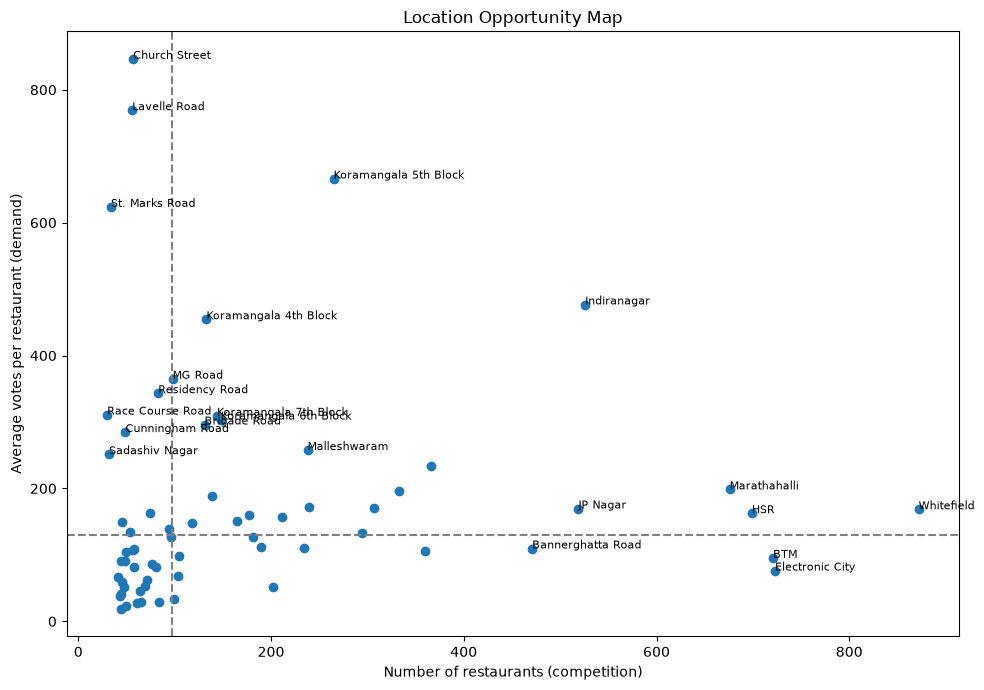

In [6]:
plt.figure(figsize=(10, 7))
plt.scatter(loc["restaurants"], loc["avg_votes"])
for _, r in loc.iterrows():
    if r["avg_votes"] > 250 or r["restaurants"] > 450:
        plt.annotate(r["location"], (r["restaurants"], r["avg_votes"]), fontsize=8)
plt.axvline(loc["restaurants"].median(), color="grey", linestyle="--")
plt.axhline(loc["avg_votes"].median(), color="grey", linestyle="--")
plt.xlabel("Number of restaurants (competition)")
plt.ylabel("Average votes per restaurant (demand)")
plt.title("Location Opportunity Map")
plt.tight_layout()
plt.savefig("../dashboard/location_opportunity_map.png", dpi=150)
plt.show()

In [4]:
c = df.assign(cuisine=df["cuisines"].str.split(",")).explode("cuisine")
c["cuisine"] = c["cuisine"].str.strip()

cuisine = (c.groupby("cuisine")
             .agg(restaurants=("name", "count"),
                  avg_rating=("rating", "mean"),
                  median_votes=("votes", "median"),
                  total_votes=("votes", "sum"))
             .reset_index())
cuisine["avg_votes"] = cuisine["total_votes"] / cuisine["restaurants"]
cuisine = cuisine[cuisine["restaurants"] >= 50].round(2)

cuisine.sort_values("restaurants", ascending=False).head(10)   # supply
cuisine.sort_values("avg_votes", ascending=False).head(10)     # demand per restaurant
cuisine.sort_values("avg_rating", ascending=False).head(10)    # quality

,cuisine,restaurants,avg_rating,median_votes,total_votes,avg_votes
63,Mediterranean,89,4.20,654.0,138207,1552.89
32,European,110,4.16,657.5,152409,1385.54
6,Asian,207,4.09,268.0,159363,769.87
95,Steak,78,4.04,613.0,97207,1246.24
10,BBQ,156,3.99,114.5,160822,1030.91
3,American,226,3.98,384.5,245495,1086.26
64,Mexican,108,3.93,102.5,53841,498.53
34,Finger Food,179,3.93,137.0,131997,737.41
86,Salad,203,3.92,197.0,140700,693.10
29,Continental,955,3.89,133.0,523789,548.47


In [5]:
bins = [0, 300, 600, 1000, float("inf")]
labels = ["Budget (up to 300)", "Mid (301-600)", "Upper-mid (601-1000)", "Premium (1000+)"]
df["price_band"] = pd.cut(df["cost_for_two"], bins=bins, labels=labels)

price = (df.groupby("price_band", observed=True)
           .agg(restaurants=("name", "count"),
                avg_rating=("rating", "mean"),
                median_votes=("votes", "median"),
                total_votes=("votes", "sum"))
           .round(2))
price["avg_votes"] = (price["total_votes"] / price["restaurants"]).round(1)
price

,restaurants,avg_rating,median_votes,total_votes,avg_votes
price_band,,,,,
Budget (up to 300),5112,3.54,8.0,226211,44.3
Mid (301-600),4852,3.57,31.0,612216,126.2
Upper-mid (601-1000),1615,3.71,131.0,604713,374.4
Premium (1000+),797,4.10,442.0,806432,1011.8


In [7]:
loc.sort_values("avg_votes", ascending=False)[["location", "restaurants", "avg_votes", "median_votes", "median_cost"]].head(15)

,location,restaurants,avg_votes,median_votes,median_cost
12,Church Street,57,846.63,202.0,750.0
51,Lavelle Road,56,769.34,319.5,1200.0
45,Koramangala 5th Block,265,666.31,122.0,500.0
81,St. Marks Road,34,623.76,175.5,650.0
27,Indiranagar,526,476.86,73.0,500.0
44,Koramangala 4th Block,133,454.57,59.0,500.0
52,MG Road,98,365.09,80.5,800.0
70,Residency Road,83,343.30,79.0,600.0
66,Race Course Road,30,311.10,64.0,1000.0
47,Koramangala 7th Block,144,309.30,60.0,500.0


In [8]:
cuisine_cost = c.groupby("cuisine")["cost_for_two"].median().rename("median_cost")
cuisine = cuisine.merge(cuisine_cost, on="cuisine")
cuisine.sort_values("avg_rating", ascending=False)[["cuisine", "restaurants", "avg_rating", "median_votes", "median_cost"]].head(10)

,cuisine,restaurants,avg_rating,median_votes,median_cost
25,Mediterranean,89,4.20,654.0,1500.0
14,European,110,4.16,657.5,1500.0
3,Asian,207,4.09,268.0,1200.0
37,Steak,78,4.04,613.0,1000.0
4,BBQ,156,3.99,114.5,725.0
0,American,226,3.98,384.5,700.0
26,Mexican,108,3.93,102.5,600.0
16,Finger Food,179,3.93,137.0,1300.0
33,Salad,203,3.92,197.0,600.0
12,Continental,955,3.89,133.0,800.0


In [9]:
key = ["Church Street", "Lavelle Road", "St. Marks Road", "MG Road", "Koramangala 5th Block", "Indiranagar", "Whitefield", "BTM"]
pd.crosstab(df["location"], df["price_band"]).reindex(key)

price_band,Budget (up to 300),Mid (301-600),Upper-mid (601-1000),Premium (1000+)
location,,,,
Church Street,10,13,21,13
Lavelle Road,3,14,7,32
St. Marks Road,8,9,9,8
MG Road,20,23,22,33
Koramangala 5th Block,88,90,56,31
Indiranagar,168,175,105,78
Whitefield,300,369,114,89
BTM,382,281,48,10


In [10]:
mid = df[df["price_band"] == "Mid (301-600)"]
(mid.groupby("location")
    .agg(restaurants=("name", "count"), median_votes=("votes", "median"))
    .query("restaurants >= 20")
    .sort_values("median_votes", ascending=False)
    .head(10))

,restaurants,median_votes
location,,
Koramangala 5th Block,90,155.5
Jeevan Bhima Nagar,38,143.0
Jayanagar,127,90.0
"ITPL Main Road, Whitefield",25,81.0
Malleshwaram,69,81.0
Basavanagudi,54,71.0
Residency Road,33,70.0
Koramangala 6th Block,64,69.5
Indiranagar,175,66.0


In [11]:
c = df.assign(cuisine=df["cuisines"].str.split(",")).explode("cuisine")
c["cuisine"] = c["cuisine"].str.strip()

top15 = cuisine.sort_values("restaurants", ascending=False).head(15)["cuisine"]
(c[c["cuisine"].isin(top15)]
   .groupby(["cuisine", "price_band"], observed=True)
   .agg(restaurants=("name", "count"), median_votes=("votes", "median"), avg_rating=("rating", "mean"))
   .query("restaurants >= 20").round(2)
   .sort_values("median_votes", ascending=False).head(15))

,,restaurants,median_votes,avg_rating
cuisine,price_band,,,
Italian,Premium (1000+),145,662.0,4.18
Pizza,Premium (1000+),58,545.5,4.25
Cafe,Premium (1000+),30,522.0,4.13
Chinese,Premium (1000+),223,449.0,4.02
Continental,Premium (1000+),342,434.5,4.06
North Indian,Premium (1000+),405,426.0,4.07
Italian,Upper-mid (601-1000),158,285.0,3.92
Beverages,Upper-mid (601-1000),93,265.0,4.00
South Indian,Premium (1000+),82,209.0,3.98


In [12]:
lp = (df.groupby(["location", "price_band"], observed=True)
        .agg(restaurants=("name", "count"), median_votes=("votes", "median"), avg_rating=("rating", "mean"))
        .reset_index())
lp = lp[lp["restaurants"] >= 15].round(2)
lp.sort_values("median_votes", ascending=False).head(15)

,location,price_band,restaurants,median_votes,avg_rating
161,Koramangala 5th Block,Premium (1000+),31,1774.0,4.34
103,Indiranagar,Premium (1000+),78,1071.0,4.20
266,Sarjapur Road,Premium (1000+),22,968.0,4.27
181,Lavelle Road,Premium (1000+),32,871.5,4.21
111,JP Nagar,Premium (1000+),25,842.0,4.08
157,Koramangala 4th Block,Premium (1000+),15,767.0,4.21
196,Malleshwaram,Premium (1000+),24,752.5,4.19
200,Marathahalli,Premium (1000+),37,746.0,4.17
84,HSR,Premium (1000+),17,732.0,4.20
119,Jayanagar,Premium (1000+),15,584.0,4.03


In [13]:
import pandas as pd

df = pd.read_csv("../data/clean/zomato_clean.csv")

bins = [0, 300, 600, 1000, float("inf")]
labels = ["1 Budget (up to 300)", "2 Mid (301-600)", "3 Upper-mid (601-1000)", "4 Premium (1000+)"]
df["price_band"] = pd.cut(df["cost_for_two"], bins=bins, labels=labels)

df.to_csv("../data/clean/zomato_dashboard.csv", index=False)
print(df.shape)

(12376, 12)
